In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
import pandas as pd

## Initializing the Max-Cut example
#### (same 3-node problem instance considered in `MaxCut-QUBO-BruteForce.ipynb`)

In [2]:
# Example graph with 3 nodes and weighted edges
edge_dict = {
    ('A', 'B'): 8,
    ('A', 'C'): -2,
    ('B', 'C'): -3
}

G = nx.Graph()

for (u, v), weight in edge_dict.items():
    G.add_edge(u, v, weight=weight)

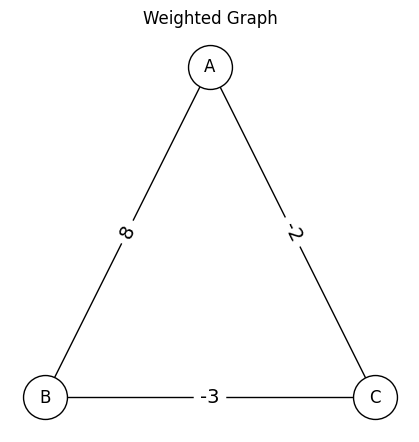

In [3]:
plt.figure(figsize=(4,4))
# Custom layout: node A at top, nodes B and C at bottom horizontally
pos = {'A': (0.5, 1.0),'B': (0, 0),'C': (1, 0)}
# Draw the graph
nx.draw(G, pos, with_labels=True, node_color="white", node_size=1000, edgecolors="black", linewidths=1)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=14)
plt.title("Weighted Graph")
plt.show()

Given a connected, undirected, weighted graph, the goal is to split the set of vertices into two mutually exclusive subsets by cutting the edges such that the sum of the edges that are cut is maximum.

## Computing the QUBO matrix Q for the MaxCut problem

In [4]:
def get_maxcut_qubo_matrix(W):
    """Computes the QUBO matrix for the Maximum Cut problem given a weight matrix W."""
    n = W.shape[0]  # Number of nodes
    Q = np.zeros((n, n))  # Initialize QUBO matrix
    for i in range(n):
        Q[i, i] = np.sum(-W[i])  # Diagonal terms (degree of node)
        for j in range(n):
            if i != j:
                Q[i, j] = W[i, j]  # Off-diagonal terms (negative adjacency)
    return Q

Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())
Q

array([[-6.,  8., -2.],
       [ 8., -5., -3.],
       [-2., -3.,  5.]])

## Solving using Gurobi

In [5]:
# ! pip install gurobipy==13.0.2

In [6]:
import gurobipy as gp
from gurobipy import GRB

In [7]:
# Initialize Gurobi model
model = gp.Model("QUBO")

# Silence Gurobi model printing metadata
# model.setParam("OutputFlag", 0)

# Create binary variables
n = Q.shape[0]
x = model.addMVar(n, vtype=GRB.BINARY, name="x")

# Add the objective function
obj = x @ Q @ x
model.setObjective(obj, GRB.MINIMIZE)

# Optimize the model
model.optimize()

# Extract the optimal solution
# optimal_solution = np.array([x[i].x for i in range(n)])
optimal_solution = x.X.astype(int)
print("Optimal solution (binary vector):", optimal_solution)
print("Optimal cost:", model.objVal)

Set parameter Username
Academic license - for non-commercial use only - expires 2027-02-20
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (win64 - Windows 11.0 (22631.2))

CPU model: 12th Gen Intel(R) Core(TM) i7-12800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 0 rows, 3 columns and 0 nonzeros (Min)
Model fingerprint: 0x9f009166
Model has 0 linear objective coefficients
Model has 6 quadratic objective terms
Variable types: 0 continuous, 3 integer (3 binary)
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [0e+00, 0e+00]
  QObjective range [8e+00, 3e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [0e+00, 0e+00]

Found heuristic solution: objective 0.0000000
Found heuristic solution: objective -6.0000000
Presolve removed 0 rows and 3 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds 

## Visualizing the MaxCut Solution

The optimal binary vector partitions the graph into two sets:
- Nodes with $ x_i = 0 $
- Nodes with $ x_i = 1 $

We can highlight the cut edges in red color


['green', 'blue', 'blue']
[('A', 'B'), ('A', 'C')]


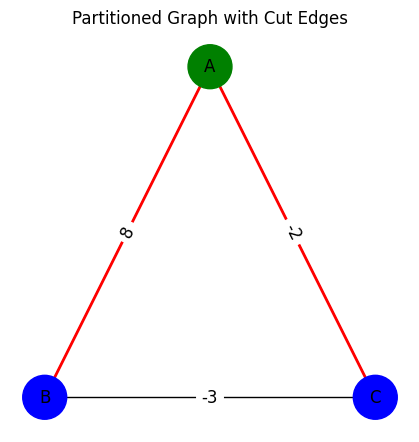

In [8]:
# Get sorted node labels to match the order of optimal_x
node_labels = sorted(list(G.nodes()))

# Identify nodes in each partition using actual node labels
partition_0 = [node_labels[i] for i, val in enumerate(optimal_solution) if val == 0]
partition_1 = [node_labels[i] for i, val in enumerate(optimal_solution) if val == 1]

# Assign colors to nodes based on partition
node_colors = []
for node in node_labels:
    if node in partition_0:
        node_colors.append("green")  # Nodes in partition 0
    elif node in partition_1:
        node_colors.append("blue")   # Nodes in partition 1
print(node_colors)
# Highlight the edges in the cut
cut_edges = [(u, v) for u, v in G.edges if (u in partition_0 and v in partition_1) or (u in partition_1 and v in partition_0)]
print(cut_edges)
# Plot the graph with node colors and cut edges
plt.figure(figsize=(4, 4))
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1000)
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, edge_color="red", width=2)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)
plt.title("Partitioned Graph with Cut Edges")
plt.show()

## Let's benchmark the runtime complexity

In [14]:
def generate_graph(num_nodes, weight_range=(-1, 1), random_seed=123):
    """
    Generate a random weighted graph.
    :param num_nodes: Number of nodes in the graph.
    :param weight_range: Range of weights for the edges (tuple, inclusive).
    :param random_seed: Seed for the random number generator.
    :return: Dictionary {(i, j): weight} representing the edges and their weights.
    """
    np.random.seed(random_seed)
    edge_dict = {}
    for i in range(1, num_nodes + 1):
        for j in range(i + 1, num_nodes + 1):
            weight = round(np.random.uniform(weight_range[0], weight_range[1]), 2)
            edge_dict[(i, j)] = weight
    G = nx.Graph()
    
    for (u, v), weight in edge_dict.items():
        G.add_edge(u, v, weight=weight)
    return G, edge_dict

In [ ]:
def qubo_gurobi_solver(Q):
    n = Q.shape[0]
    model = gp.Model("QUBO")
    model.setParam("OutputFlag", 0)
    # model.setParam("LogToConsole", 0)
    x = model.addMVar(n, vtype=GRB.BINARY, name="x")

    obj = x @ Q @ x
    model.setObjective(obj, GRB.MINIMIZE)

    # Model Parameters Guidelines: https://docs.gurobi.com/projects/optimizer/en/current/concepts/parameters/guidelines.html

    # Set an Acceptable MIP Gap (https://docs.gurobi.com/projects/optimizer/en/current/reference/parameters.html#mipgap):
    # Stops when the solution is within 1% of the proven optimal (default is 0.0001 / 0.01%).
    # model.Params.MIPGap = 0.1

    # Optimize the model
    model.optimize()

    if model.Status == GRB.OPTIMAL:
        return x.X.astype(int), model.ObjVal
    else:
        return None, None

In [16]:
import time

benchmark_rows = []

for num_nodes in range(1, 41):
    print(f"Running benchmark for {num_nodes} nodes...")
    G, edge_dict = generate_graph(num_nodes, random_seed=123)
    G.add_nodes_from(range(1, num_nodes + 1))
    Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())

    start_time = time.perf_counter()
    optimal_x, cost = qubo_gurobi_solver(Q)
    runtime_seconds = time.perf_counter() - start_time

    benchmark_rows.append({
        "num_nodes": num_nodes,
        "optimal_x": ''.join(str(int(v)) for v in optimal_x) if optimal_x is not None else None,
        "cost": round(float(cost), 2) if cost is not None else None,
        "runtime_seconds": round(runtime_seconds, 6),
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

Running benchmark for 1 nodes...
Running benchmark for 2 nodes...
Running benchmark for 3 nodes...
Running benchmark for 4 nodes...
Running benchmark for 5 nodes...
Running benchmark for 6 nodes...
Running benchmark for 7 nodes...
Running benchmark for 8 nodes...
Running benchmark for 9 nodes...
Running benchmark for 10 nodes...
Running benchmark for 11 nodes...
Running benchmark for 12 nodes...
Running benchmark for 13 nodes...
Running benchmark for 14 nodes...
Running benchmark for 15 nodes...
Running benchmark for 16 nodes...
Running benchmark for 17 nodes...
Running benchmark for 18 nodes...
Running benchmark for 19 nodes...
Running benchmark for 20 nodes...
Running benchmark for 21 nodes...
Running benchmark for 22 nodes...
Running benchmark for 23 nodes...
Running benchmark for 24 nodes...
Running benchmark for 25 nodes...
Running benchmark for 26 nodes...
Running benchmark for 27 nodes...
Running benchmark for 28 nodes...
Running benchmark for 29 nodes...
Running benchmark for 3

,num_nodes,optimal_x,cost,runtime_seconds
0,1,0,0.00,0.000888
1,2,01,-0.39,0.000991
2,3,111,-0.00,0.000883
3,4,1011,-0.93,0.000744
4,5,10111,-1.64,0.000790
5,6,101111,-1.53,0.000748
6,7,1011011,-1.77,0.003744
7,8,01000111,-3.08,0.005832
8,9,011011111,-3.40,0.006021
9,10,1111001001,-3.94,0.009213


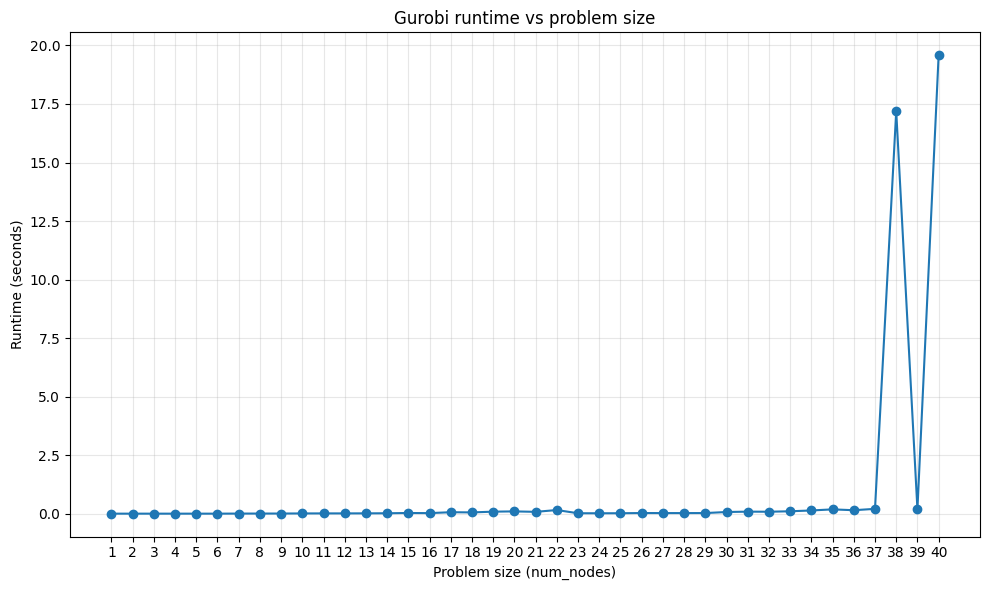

In [13]:
plt.figure(figsize=(10, 6))
plt.plot(benchmark_df["num_nodes"], benchmark_df["runtime_seconds"], marker="o")
plt.xticks(benchmark_df["num_nodes"])
plt.xlabel("Problem size (num_nodes)")
plt.ylabel("Runtime (seconds)")
plt.title("Gurobi runtime vs problem size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()